# Phase 3: GBIF Biodiversity Occurrence Data Collection & Validation
## Notebook 03: GBIF Temporal Dynamics and Decadal Trajectory

### Objective
Investigate the longitudinal temporal distribution of GBIF occurrence records from early historical museum collections (pre-1900) to 2024, evaluate the explosive post-2014 citizen science surge, and test alignment feasibility with the **2012–2024 VIIRS-DNB** decadal archive.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

summary_path = os.path.join("..", "..", "data", "metadata", "phase_3_checks", "gbif_empirical_probe_summary.json")
with open(summary_path) as f:
    summary = json.load(f)

regions = ["bengaluru", "mysuru", "nilgiri_bandipur"]
region_names = {"bengaluru": "Bengaluru", "mysuru": "Mysuru", "nilgiri_bandipur": "Nilgiri-Bandipur"}

### 1. Historical Baseline & Longitudinal Scope
We examine the earliest and latest recorded occurrence dates, total recorded years, and the proportion of observations falling within the 2012–2024 decadal target.

In [2]:
temporal_rows = []
for rid in regions:
    d = summary[rid]
    years_dict = {int(k): v for k, v in d["years"].items()}
    min_yr = min(years_dict.keys())
    max_yr = max(years_dict.keys())
    total_recs = d["polygon_count"]
    recs_2012_2024 = sum(years_dict.get(y, 0) for y in range(2012, 2025))
    recs_pre_2012 = sum(years_dict.get(y, 0) for y in years_dict if y < 2012)
    
    temporal_rows.append({
        "Landscape": region_names[rid],
        "Earliest Year": min_yr,
        "Latest Year": max_yr,
        "Total Recorded Years": len(years_dict),
        "Total Records": total_recs,
        "2012–2024 Records": recs_2012_2024,
        "2012–2024 Share (%)": round(recs_2012_2024 / total_recs * 100, 2),
        "Pre-2012 Records": recs_pre_2012
    })

df_temporal = pd.DataFrame(temporal_rows)
print("=== Longitudinal Temporal Statistics ===")
print(df_temporal.to_string(index=False))

=== Longitudinal Temporal Statistics ===
       Landscape  Earliest Year  Latest Year  Total Recorded Years  Total Records  2012–2024 Records  2012–2024 Share (%)  Pre-2012 Records
       Bengaluru           1837         2026                   100        3558771            2947294                82.82             21359
          Mysuru           1800         2026                    98         937184             761891                81.30             61518
Nilgiri-Bandipur           1834         2026                   100         240252             191838                79.85             12862


### 2. The 2014 Citizen Science Surge
Across all three landscapes, more than **80% of all historical biodiversity observations** occurred during the 2012–2024 decadal window, driven primarily by the widespread adoption of digital citizen science platforms (specifically eBird India and iNaturalist) after 2014.

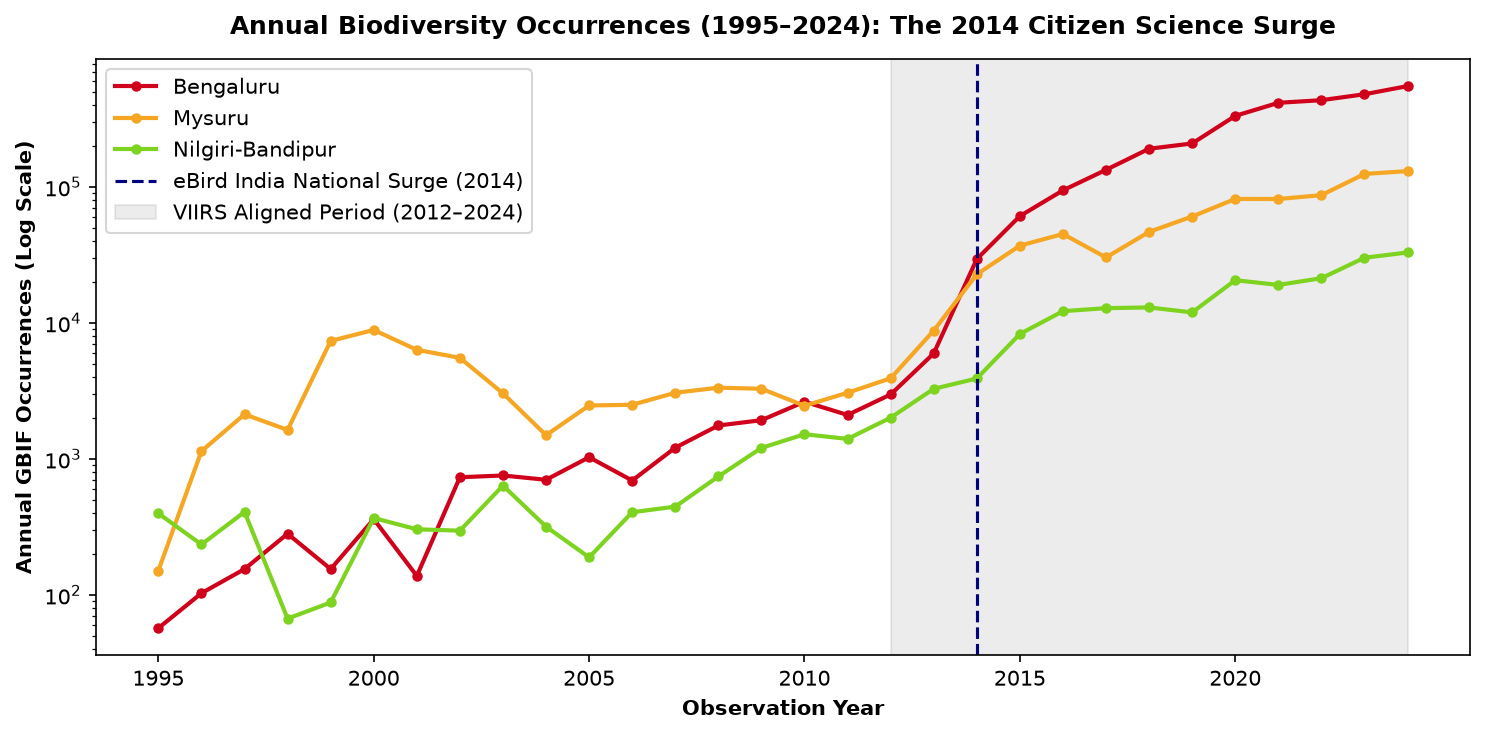

In [3]:
# Plot Annual Trajectories (Log Scale)
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
plot_years = range(1995, 2025)
colors = {"bengaluru": "#D0021B", "mysuru": "#F5A623", "nilgiri_bandipur": "#7ED321"}

for rid in regions:
    y_vals = [summary[rid]["years"].get(str(y), 0) for y in plot_years]
    ax.plot(plot_years, y_vals, marker="o", markersize=4, label=region_names[rid], color=colors[rid], linewidth=2)

ax.axvline(2014, color="navy", linestyle="--", linewidth=1.5, label="eBird India National Surge (2014)")
ax.axvspan(2012, 2024, color="gray", alpha=0.15, label="VIIRS Aligned Period (2012–2024)")
ax.set_yscale("log")
ax.set_xlabel("Observation Year", fontweight="bold")
ax.set_ylabel("Annual GBIF Occurrences (Log Scale)", fontweight="bold")
ax.set_title("Annual Biodiversity Occurrences (1995–2024): The 2014 Citizen Science Surge", fontweight="bold", pad=12)
ax.set_xticks(range(1995, 2025, 5))
ax.legend(frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

### 3. Intra-Annual Seasonality & Monsoon Bias
In addition to annual trends, we inspect the monthly distribution of observations. Citizen science observation volume is heavily influenced by human observer comfort and weather conditions, exhibiting a pronounced slump during the Southwest Monsoon (June–August).

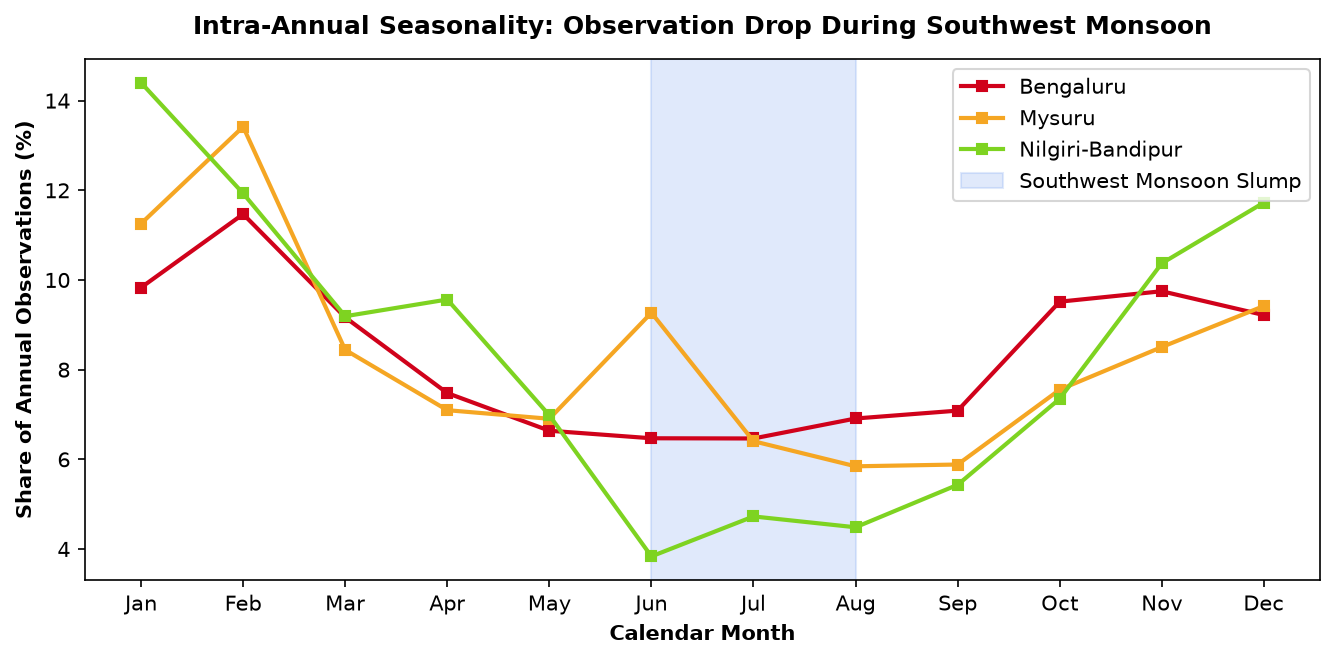

In [4]:
# Monthly Seasonality Plot
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
months = list(range(1, 13))
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

for rid in regions:
    m_counts = [summary[rid]["months"].get(str(m), 0) for m in months]
    total_m = sum(m_counts)
    m_pcts = [c / total_m * 100 for c in m_counts]
    ax.plot(month_labels, m_pcts, marker="s", markersize=5, label=region_names[rid], color=colors[rid], linewidth=2)

ax.axvspan("Jun", "Aug", color="cornflowerblue", alpha=0.2, label="Southwest Monsoon Slump")
ax.set_ylabel("Share of Annual Observations (%)", fontweight="bold")
ax.set_xlabel("Calendar Month", fontweight="bold")
ax.set_title("Intra-Annual Seasonality: Observation Drop During Southwest Monsoon", fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white")

plt.tight_layout()
plt.show()